1.读取地震数据，按震级从大到小进行排序，选出震级位列前50的地震位置。使用以太平洋为中心的 Robinson 投影，根据经纬度标出震级位列前50的地震，用颜色表示震级大小，颜色越深，震级越高，并添加标题和颜色条，展示强震的全球分布。

<function matplotlib.pyplot.show(close=None, block=None)>

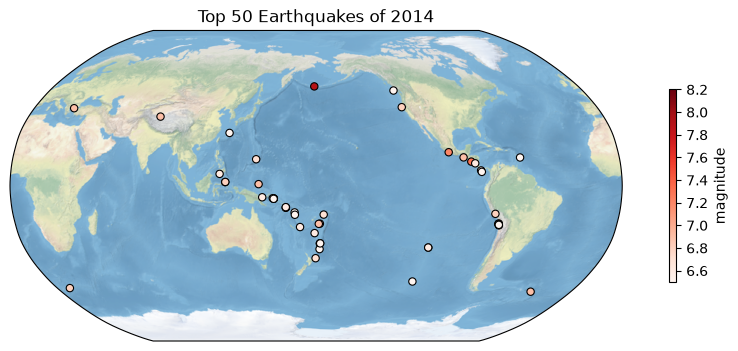

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
#读取文件
data = pd.read_csv(r"usgs_earthquakes.csv")
#读取震级在前50的地震数据
top50 = data.sort_values("mag",ascending=False,kind="stable").head(50)
# 4. 分别取出经度、纬度和震级
longitude = top50["longitude"]
latitude = top50["latitude"]
magnitude = top50["mag"]
# 5. 创建世界地图
plt.figure(figsize=(10, 5))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ax.set_global()
ax.stock_img()
# 6. 在地图上画出地震位置
points = ax.scatter(longitude,latitude,c=magnitude,cmap="Reds",s=28,edgecolors="black",linewidths=0.8,transform=ccrs.PlateCarree() )
colorbar = plt.colorbar(points,ax=ax,shrink=0.5,pad=0.06,aspect=25)
colorbar.set_label("magnitude")
# 7. 添加颜色条和标题
colorbar.set_ticks([6.6, 6.8, 7.0, 7.2, 7.4,7.6, 7.8, 8.0, 8.2])
plt.title("Top 50 Earthquakes of 2014")
plt.show

读取NetCDF文件，提取2026年7月（FLDAS_NOAH01_CP_GL_M.A202607.001.nc）的全球大陆月平均气温（南纬60度、西经180度，北纬90度，东经180度），并将开尔文转换为摄氏度。采用等经纬度投影绘制全球气温分布，缺失区域显示为浅灰色。同时添加经纬度标签和刻度、标题、经纬网、海岸线、图例、颜色条、深圳位置注释和数据说明文本框。我是使用h5netcdf，因为我的环境使用netCDF4会报错,由于文件大于25MB，所以我将源文件放在了Github的仓库的Release附件里

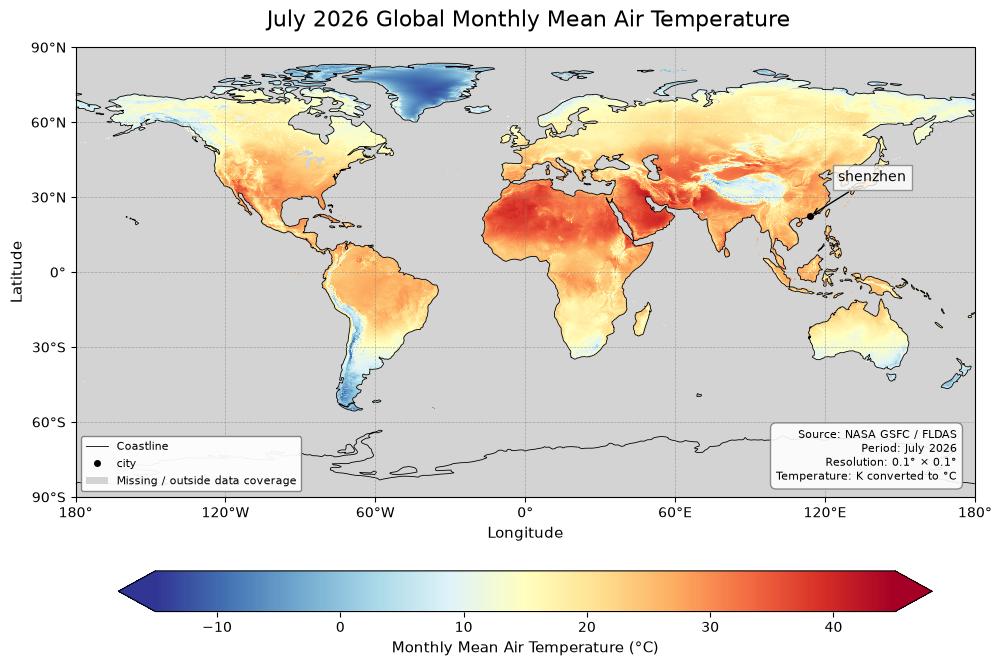

In [5]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
#读取文件
data = xr.open_dataset(r"FLDAS_NOAH01_CP_GL_M.A202607.001.nc",engine="h5netcdf")
#提取月平均气温，转换成摄氏度
temperature = data["Tair_f_tavg"].isel(time=0) - 273.15
#地图投影：等经纬度投影
fig = plt.figure(figsize=(14, 8))
ax = fig.add_subplot(1,1,1, projection=ccrs.PlateCarree())
ax.set_global()
#缺失值和数据范围以外的区域显示为浅灰色
ax.set_facecolor("lightgray")
#绘制月平均气温，NaN 自动留空
image = ax.pcolormesh(data["X"],data["Y"],temperature,transform=ccrs.PlateCarree(),cmap="RdYlBu_r",shading="auto",vmin=-15,vmax=45)
#x轴标签
ax.set_xlabel("Longitude", fontsize=11)
#x轴刻度
ax.set_xticks([-180, -120, -60, 0, 60, 120, 180],crs=ccrs.PlateCarree())
ax.xaxis.set_major_formatter(LongitudeFormatter())
#y轴标签和刻度
ax.set_ylabel("Latitude", fontsize=11)
ax.set_yticks([-90, -60, -30, 0, 30, 60, 90],crs=ccrs.PlateCarree())
ax.yaxis.set_major_formatter(LatitudeFormatter())
#标题
ax.set_title(" July 2026 Global Monthly Mean Air Temperature",fontsize=16,pad=15)
#经纬网
ax.gridlines(xlocs=[-180, -120, -60, 0, 60, 120, 180],ylocs=[-90, -60, -30, 0, 30, 60, 90],linewidth=0.5,color="gray",linestyle="--",alpha=0.6)
#海岸线
ax.coastlines(color="black", linewidth=0.6)
#注释：标出深圳位置
shenzhen_lon = 114.1
shenzhen_lat = 22.5
ax.plot(shenzhen_lon,shenzhen_lat,marker="o",color="black",markersize=4,transform=ccrs.PlateCarree(),zorder=5)
ax.annotate("shenzhen",xy=(shenzhen_lon, shenzhen_lat),xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),xytext=(20, 25),textcoords="offset points",arrowprops=dict(arrowstyle="->", color="black"),
    fontsize=10,bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray"))
#图例：说明线条、标记和灰色区域
legend_items = [Line2D([0], [0],color="black",linewidth=0.6,label="Coastline"),Line2D([0], [0],marker="o",color="black",linestyle="None",markersize=4,
        label="city"),Patch(facecolor="lightgray",label="Missing / outside data coverage")]
ax.legend(handles=legend_items,loc="lower left",fontsize=8,framealpha=0.95,edgecolor="gray")
#文本框：数据来源、分辨率和处理说明
ax.text(0.98, 0.03,"Source: NASA GSFC / FLDAS\n""Period: July 2026\n""Resolution: 0.1° × 0.1°\n""Temperature: K converted to °C",transform=ax.transAxes,
    ha="right",va="bottom",fontsize=8,bbox=dict(facecolor="white",edgecolor="gray",alpha=0.9,boxstyle="round,pad=0.5"))
#颜色条：说明颜色对应的气温
colorbar = fig.colorbar(image,ax=ax,orientation="horizontal",pad=0.12,shrink=0.75,extend="both")
colorbar.set_label("Monthly Mean Air Temperature (°C)", fontsize=11)
plt.show()

从同一文件中选取东经100°—125°、北纬15°—40°的区域，提取月平均气温并转换为摄氏度。采用与全球图不同的 Mercator 投影绘制区域地图，保持相同的颜色范围，便于比较，并添加与全球图一致的地图要素和说明。

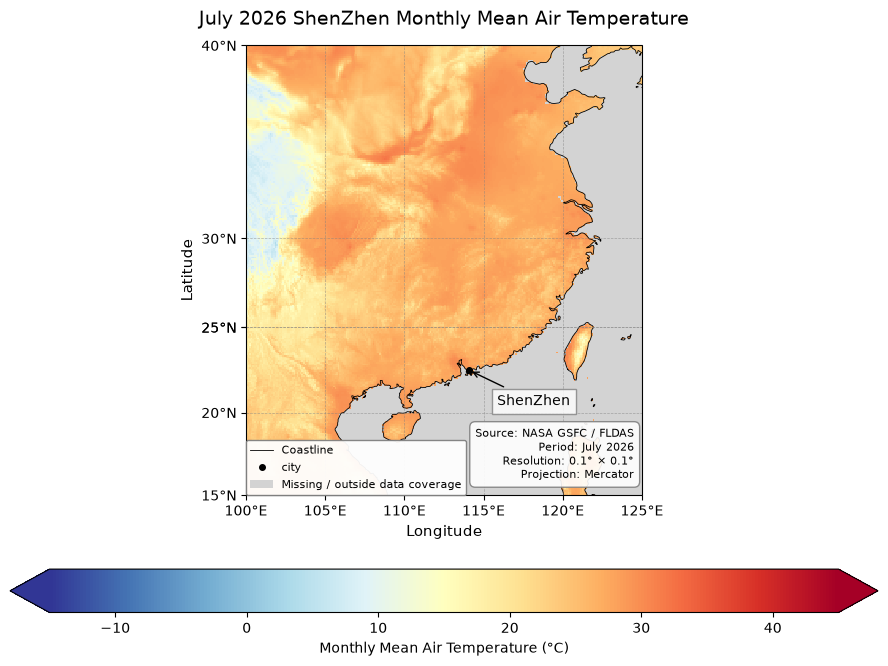

In [8]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
#读取文件
data = xr.open_dataset(r"FLDAS_NOAH01_CP_GL_M.A202607.001.nc",engine="h5netcdf")
#设置区域范围
lon_min = 100
lon_max = 125
lat_min = 15
lat_max = 40
#提取区域数据
region = data.sel(X = slice(lon_min, lon_max),Y = slice(lat_min, lat_max))
#提取月平均气温，K转换成℃
temperature = region["Tair_f_tavg"].isel(time=0) - 273.15
#创建地图：采用与全球图不同的Mercator投影
fig = plt.figure(figsize = (14, 8))
ax = fig.add_subplot(1,1,1, projection = ccrs.Mercator())
#设置地图显示范围
ax.set_extent([lon_min, lon_max, lat_min, lat_max],crs = ccrs.PlateCarree())
#缺失值位置显示浅灰色
ax.set_facecolor("lightgray")
#绘制气温
image = ax.pcolormesh(region["X"],region["Y"],temperature,transform=ccrs.PlateCarree(),cmap = "RdYlBu_r",shading = "auto",vmin = -15,vmax = 45)
#海岸线
ax.coastlines(color = "black", linewidth=0.6)
#设置坐标轴标签
ax.set_xlabel("Longitude", fontsize = 11)
ax.set_ylabel("Latitude", fontsize = 11)
#刻度位置：适用于这里的示例范围
lon_ticks = [100, 105,110, 115, 120,125]
lat_ticks = [15, 20,25,30,25,40]
ax.set_xticks(lon_ticks, crs = ccrs.PlateCarree())
ax.set_yticks(lat_ticks, crs = ccrs.PlateCarree())
#将刻度显示为经纬度格式
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())
#经纬网
ax.gridlines(xlocs = lon_ticks,ylocs = lat_ticks,linewidth = 0.5,color = "gray",linestyle = "--",alpha = 0.6)
#标题
ax.set_title("July 2026 ShenZhen Monthly Mean Air Temperature",fontsize = 14,pad = 15)
#注释：标出深圳位置
shenzhen_lon = 114.1
shenzhen_lat = 22.5
ax.plot(shenzhen_lon,shenzhen_lat,marker="o",color="black",markersize=4,transform=ccrs.PlateCarree(),zorder=5)
ax.annotate("ShenZhen",xy=(shenzhen_lon, shenzhen_lat),xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),xytext=(20, -25),textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="black"),fontsize=10,bbox=dict(facecolor="white",alpha=0.8,edgecolor="gray"))
#图例说明线条、标记和灰色区域
legend_items = [Line2D([0], [0],color="black",linewidth=0.6,label="Coastline"),Line2D([0], [0],marker="o",color="black",linestyle="None",markersize=4,
        label="city"),Patch(facecolor="lightgray",label="Missing / outside data coverage")]
ax.legend(handles=legend_items,loc=(0,0),fontsize=8,framealpha=0.95,edgecolor="gray")
#文本框：数据来源、分辨率和处理说明
ax.text(0.98, 0.03,"Source: NASA GSFC / FLDAS\n""Period: July 2026\n""Resolution: 0.1° × 0.1°\n""Projection: Mercator",transform=ax.transAxes,ha="right",
    va="bottom",fontsize=8,bbox=dict(facecolor="white",edgecolor="gray",alpha=0.9,boxstyle="round,pad=0.5"))
#颜色条:说明颜色对应的气温
colorbar = fig.colorbar(image,ax=ax,orientation="horizontal",pad=0.12,shrink=0.8,extend="both")
colorbar.set_label("Monthly Mean Air Temperature (°C)")
plt.show()